# Step 2 + 3 – Preprocessing and Feature Engineering
**Code used:** `pathsnap/preprocessing.py` (step 2) and `pathsnap/feature_engineering.py` (step 3).
**Partitions:** `train` and `student_test`.

Contents
1. Worked example on one trip — every function called separately so each step is visible
2. Preprocessing all 90 trips
3. Label and candidate quality
4. Choosing the candidate radius (train only)
5. Feature distributions and why each feature was chosen
6. Non-ML baseline: nearest road segment

In [1]:
import os, sys, time, json, warnings
sys.path.insert(0, os.path.abspath('..')); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 110
from pathsnap.data_loading import list_trips, load_trip, DATA_ROOT
print('data folder:', DATA_ROOT)
import folium
from pathsnap.preprocessing import project_trip, generate_candidates, align_route_to_points, label_candidates, RADIUS_M, K_MAX
from pathsnap.feature_engineering import gps_kinematics, build_features, build_training_table, FEATURES
OUT = os.path.abspath('../results/02_preprocessing'); MAPS = os.path.abspath('../results/maps')
FEAT_DIR = os.path.join(OUT, 'features'); os.makedirs(FEAT_DIR, exist_ok=True); os.makedirs(MAPS, exist_ok=True)
print('radius =', RADIUS_M, 'm, max candidates per point =', K_MAX)

data folder: C:\Users\amanp\Downloads\ML_Hackathon\StudentFolder\Student folder


radius = 50.0 m, max candidates per point = 10


## 1. Worked example: student-test trip 00000000

**2.1 Projection** (`project_trip`): GPS points and road nodes from lon/lat into metres around the trip centre.

In [2]:
trip = load_trip('student_test', '00000000')
geo = project_trip(trip)
print('GPS points:', geo['P'].shape, '| road nodes:', geo['N'].shape, '| arcs:', len(geo['arc_len']))
pd.DataFrame({'lon': trip['track'].lon[:5], 'lat': trip['track'].lat[:5], 'x_m': geo['P'][:5,0], 'y_m': geo['P'][:5,1]}).round(5)

GPS points: (2503, 2) | road nodes: (8542, 2) | arcs: 18196


,lon,lat,x_m,y_m
0,54.96352,56.25156,25951.79349,9600.32914
1,54.96314,56.25152,25928.51408,9596.32612
2,54.96294,56.25147,25916.06950,9590.43279
3,54.96273,56.25153,25902.94387,9597.32688
4,54.96240,56.25155,25882.32673,9599.21719


**2.2 Candidate generation** (`generate_candidates`): road segments within 50 m of each GPS point (at most 10).

In [3]:
cand = generate_candidates(geo)
print('candidate rows:', len(cand), '| points with >= 1 candidate:', cand.point_idx.nunique(), 'of', len(geo['P']))
cand[cand.point_idx < 3].round(2)

candidate rows: 10718 | points with >= 1 candidate: 2503 of 2503


,point_idx,arc_id,dist,t_along,dist_rank
0,0,17630,6.11,0.87,0
1,0,17634,6.11,0.13,1
2,0,17635,27.64,0.14,2
3,0,17668,27.64,0.86,3
4,0,212,45.96,1.00,4
5,0,17633,45.96,0.00,5
6,1,17630,0.37,0.94,0
7,1,17634,0.37,0.06,1
8,1,17635,15.64,0.06,2
9,1,17668,15.64,0.94,3


**2.3 Label alignment** (`align_route_to_points`): match every GPS point to one arc of the reference route.
Monotonic dynamic programming — the route position can only move forward — minimising the total distance.

In [4]:
gt_arc, gt_dist = align_route_to_points(geo, trip['route'])
print('reference route arcs:', len(trip['route']), '| GPS points:', len(gt_arc))
print('distance GPS point -> its reference arc: median %.1f m, max %.1f m' % (np.median(gt_dist), gt_dist.max()))
pd.DataFrame({'point_idx': range(8), 'reference_arc': gt_arc[:8], 'distance_m': gt_dist[:8].round(1)})

reference route arcs: 179 | GPS points: 2503
distance GPS point -> its reference arc: median 6.1 m, max 36.1 m


,point_idx,reference_arc,distance_m
0,0,17630,6.1
1,1,17630,0.4
2,2,17630,6.4
3,3,17633,0.6
4,4,17633,0.3
5,5,211,8.0
6,6,211,4.1
7,7,211,0.8


**3. Features** (`build_features`) and **2.4 labels** (`label_candidates`).

In [5]:
speed, heading, step, gap = gps_kinematics(geo['P'], trip['track']['t'].values)
print('speed of first points (m/s):', speed[:5].round(1), '| heading (deg):', heading[:5].round(0))
feat = build_features(geo, cand, trip['track']['t'].values)
feat, info = label_candidates(geo, feat, trip['route'])
feat[feat.point_idx < 2][['point_idx','arc_id'] + FEATURES + ['label','valid']].round(2)

speed of first points (m/s): [18.5 16.3 17.4 17.7 19.6] | heading (deg): [255. 266. 269. 283. 287.]


,point_idx,arc_id,dist,dist_rank,dist_minus_min,dist_ratio,n_cand,heading_diff,speed,arc_len,t_along,dist_prev,dist_next,gap,label,valid
0,0,17630,6.11,0,0.00,0.86,6,19.79,18.53,358.07,0.87,6.11,0.37,0.0,1,1
1,0,17634,6.11,1,0.00,0.86,6,160.21,18.53,358.07,0.13,6.11,0.37,0.0,0,1
2,0,17635,27.64,2,21.53,3.89,6,155.18,18.53,262.48,0.14,27.64,15.64,0.0,0,1
3,0,17668,27.64,3,21.53,3.89,6,24.82,18.53,262.48,0.86,27.64,15.64,0.0,0,1
4,0,212,45.96,4,39.85,6.46,6,160.09,18.53,33.16,1.00,45.96,22.64,0.0,0,1
5,0,17633,45.96,5,39.85,6.46,6,19.91,18.53,33.16,0.00,45.96,22.64,0.0,0,1
6,1,17630,0.37,0,0.00,0.27,6,7.83,16.31,358.07,0.94,6.11,6.44,1.0,1,1
7,1,17634,0.37,1,0.00,0.27,6,172.17,16.31,358.07,0.06,6.11,6.44,1.0,0,1
8,1,17635,15.64,2,15.27,11.43,6,143.21,16.31,262.48,0.06,27.64,12.08,1.0,0,1
9,1,17668,15.64,3,15.27,11.43,6,36.79,16.31,262.48,0.94,27.64,12.08,1.0,0,1


Point 0 above: several candidates, exactly one has `label = 1` (its reference arc).

## 2. Preprocessing all trips (steps 2 + 3 together: `build_training_table`)

In [6]:
tables, infos = [], {}
t0 = time.time()
for part in ['train', 'student_test']:
    for tid in list_trips(part):
        f, info = build_training_table(load_trip(part, tid))
        f['partition'] = part; tables.append(f); infos[(part, tid)] = info
cands = pd.concat(tables, ignore_index=True)
cands.to_csv(f'{FEAT_DIR}/candidates_r50_k10.csv.gz', index=False)
print('preprocessing time: %.1fs, candidate rows: %d' % (time.time() - t0, len(cands)))

preprocessing time: 123.1s, candidate rows: 1360338


## 3. Label and candidate quality

In [7]:
rows = []
for (part, tid), info in infos.items():
    sub = cands[(cands.partition==part) & (cands.trip_id==tid)]
    valid = info['valid']; n = len(valid)
    vmask = np.zeros(n, bool); vmask[sub[sub.label==1].point_idx.unique()] = True
    amask = np.zeros(n, bool); amask[sub.point_idx.unique()] = True
    rows.append(dict(partition=part, trip_id=tid, n_points=n, valid_frac=valid.mean(),
        no_candidate_frac=1 - amask.mean(), candidate_miss_rate=1 - vmask[valid].mean(),
        align_dist_median=np.median(info['gt_dist'][valid]), cands_per_point=len(sub) / n))
q = pd.DataFrame(rows); q.to_csv(f'{OUT}/label_and_candidate_quality.csv', index=False)
q.groupby('partition')[['valid_frac','no_candidate_frac','candidate_miss_rate','align_dist_median','cands_per_point']].describe().T.round(4)

partition                  student_test    train
valid_frac          count       10.0000  80.0000
                    mean         0.9993   0.9751
                    std          0.0022   0.1196
                    min          0.9932   0.1056
                    25%          1.0000   0.9994
                    50%          1.0000   1.0000
                    75%          1.0000   1.0000
                    max          1.0000   1.0000
no_candidate_frac   count       10.0000  80.0000
                    mean         0.0000   0.0143
                    std          0.0000   0.0959
                    min          0.0000   0.0000
                    25%          0.0000   0.0000
                    50%          0.0000   0.0000
                    75%          0.0000   0.0000
                    max          0.0000   0.8553
candidate_miss_rate count       10.0000  80.0000
                    mean         0.0016   0.0087
                    std          0.0031   0.0312
                    min          0.0000   0.0000
                    25%          0.0000   0.0000
                    50%          0.0001   0.0006
                    75%          0.0011   0.0022
                    max          0.0095   0.2009
align_dist_median   count       10.0000  80.0000
                    mean         5.0782   5.0380
                    std          0.9128   1.3133
                    min          4.1674   3.4511
                    25%          4.4253   4.2662
                    50%          4.7229   4.6293
                    75%          5.7736   5.4002
                    max          6.8281  11.2454
cands_per_point     count       10.0000  80.0000
                    mean         7.1119   7.0901
                    std          2.1272   1.7815
                    min          3.5148   1.2057
                    25%          5.3462   6.2034
                    50%          8.0432   7.1776
                    75%          8.5209   8.6275
                    max          9.1534   9.7085

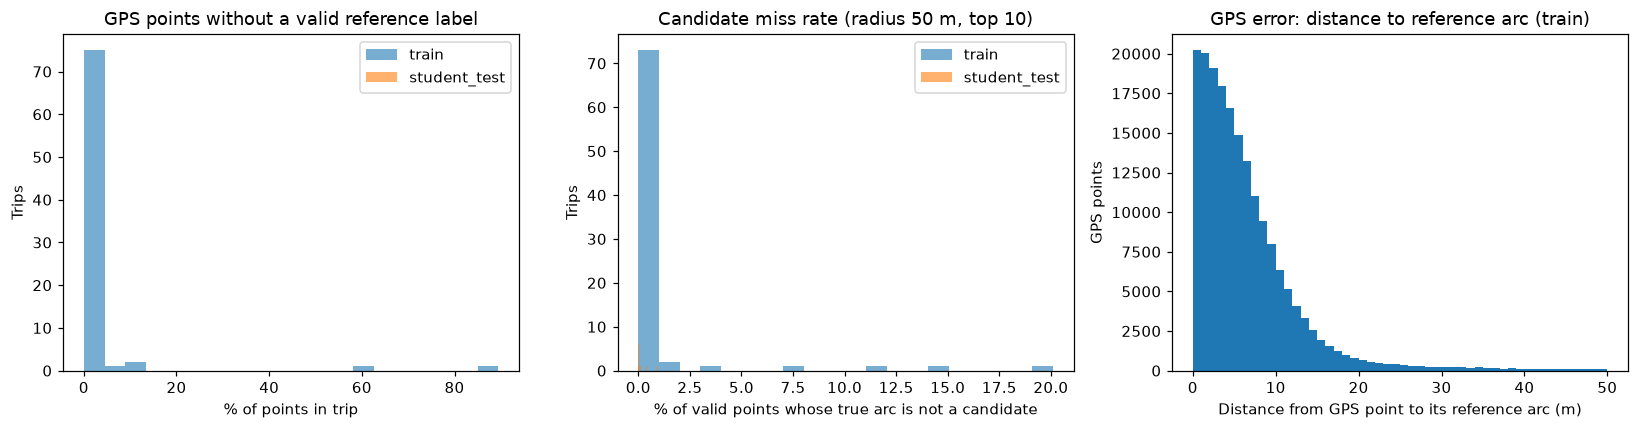

GPS-to-reference distance (train, valid points): median 4.9 m, 90% 13.2 m, 99% 34.6 m


In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for part, col in [('train','tab:blue'), ('student_test','tab:orange')]:
    s = q[q.partition==part]
    ax[0].hist(100 * (1 - s.valid_frac), bins=20, color=col, alpha=.6, label=part)
    ax[1].hist(100 * s.candidate_miss_rate, bins=20, color=col, alpha=.6, label=part)
ax[0].set_title('GPS points without a valid reference label'); ax[0].set_xlabel('% of points in trip'); ax[0].set_ylabel('Trips'); ax[0].legend()
ax[1].set_title(f'Candidate miss rate (radius {RADIUS_M:.0f} m, top {K_MAX})'); ax[1].set_xlabel('% of valid points whose true arc is not a candidate'); ax[1].set_ylabel('Trips'); ax[1].legend()
gd = np.concatenate([infos[k]['gt_dist'][infos[k]['valid']] for k in infos if k[0]=='train'])
ax[2].hist(gd, bins=50, color='tab:blue'); ax[2].set_title('GPS error: distance to reference arc (train)')
ax[2].set_xlabel('Distance from GPS point to its reference arc (m)'); ax[2].set_ylabel('GPS points')
plt.tight_layout(); plt.savefig(f'{OUT}/label_quality.png'); plt.show()
print('GPS-to-reference distance (train, valid points): median %.1f m, 90%% %.1f m, 99%% %.1f m' % tuple(np.percentile(gd, [50, 90, 99])))

## 4. Choosing the candidate radius (20 train trips)

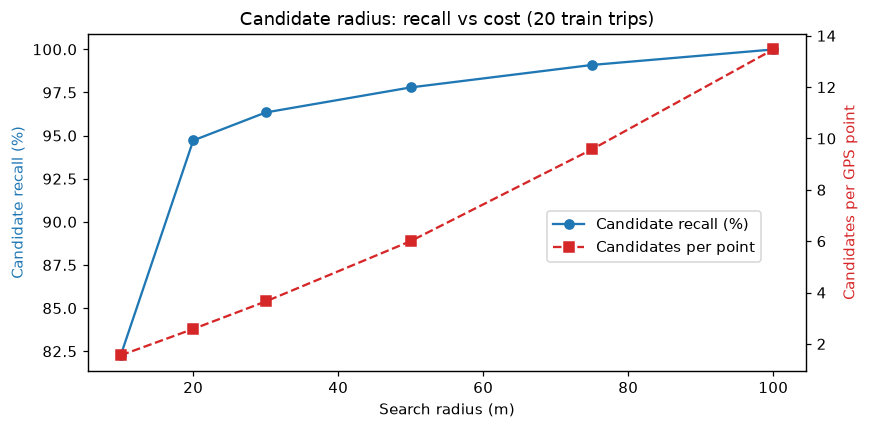

,radius_m,candidate_recall,cands_per_point
0,10,0.8226,1.5531
1,20,0.9472,2.5809
2,30,0.9634,3.6519
3,50,0.9779,6.0034
4,75,0.9909,9.5768
5,100,0.9999,13.4657


In [9]:
sweep = []
train_ids = list_trips('train')[::4]
for r in [10, 20, 30, 50, 75, 100]:
    hit = tot = ncand = npts = 0
    for tid in train_ids:
        info = infos[('train', tid)]
        c = generate_candidates(info['geo'], radius=r, k_max=50)
        v = info['gt_dist'] <= 100            # fixed, independent of r, so recall is not circular
        ok = c[c.arc_id.values == info['gt_arc'][c.point_idx.values]].point_idx.unique()
        m_ = np.zeros(len(v), bool); m_[ok] = True
        hit += m_[v].sum(); tot += v.sum(); ncand += len(c); npts += len(v)
    sweep.append(dict(radius_m=r, candidate_recall=hit / tot, cands_per_point=ncand / npts))
sweep = pd.DataFrame(sweep); sweep.to_csv(f'{OUT}/radius_sweep.csv', index=False)
fig, ax1 = plt.subplots(figsize=(8, 4)); ax2 = ax1.twinx()
ax1.plot(sweep.radius_m, 100 * sweep.candidate_recall, 'o-', color='tab:blue', label='Candidate recall (%)')
ax2.plot(sweep.radius_m, sweep.cands_per_point, 's--', color='tab:red', label='Candidates per point')
ax1.set_xlabel('Search radius (m)'); ax1.set_ylabel('Candidate recall (%)', color='tab:blue'); ax2.set_ylabel('Candidates per GPS point', color='tab:red')
ax1.set_title('Candidate radius: recall vs cost (20 train trips)')
fig.legend(loc='center right', bbox_to_anchor=(0.88, 0.45)); plt.tight_layout(); plt.savefig(f'{OUT}/radius_sweep.png'); plt.show(); sweep.round(4)

## 5. Class balance and feature distributions (train, valid points)

positives: 183940  negatives: 1016185  -> positive share 15.3%


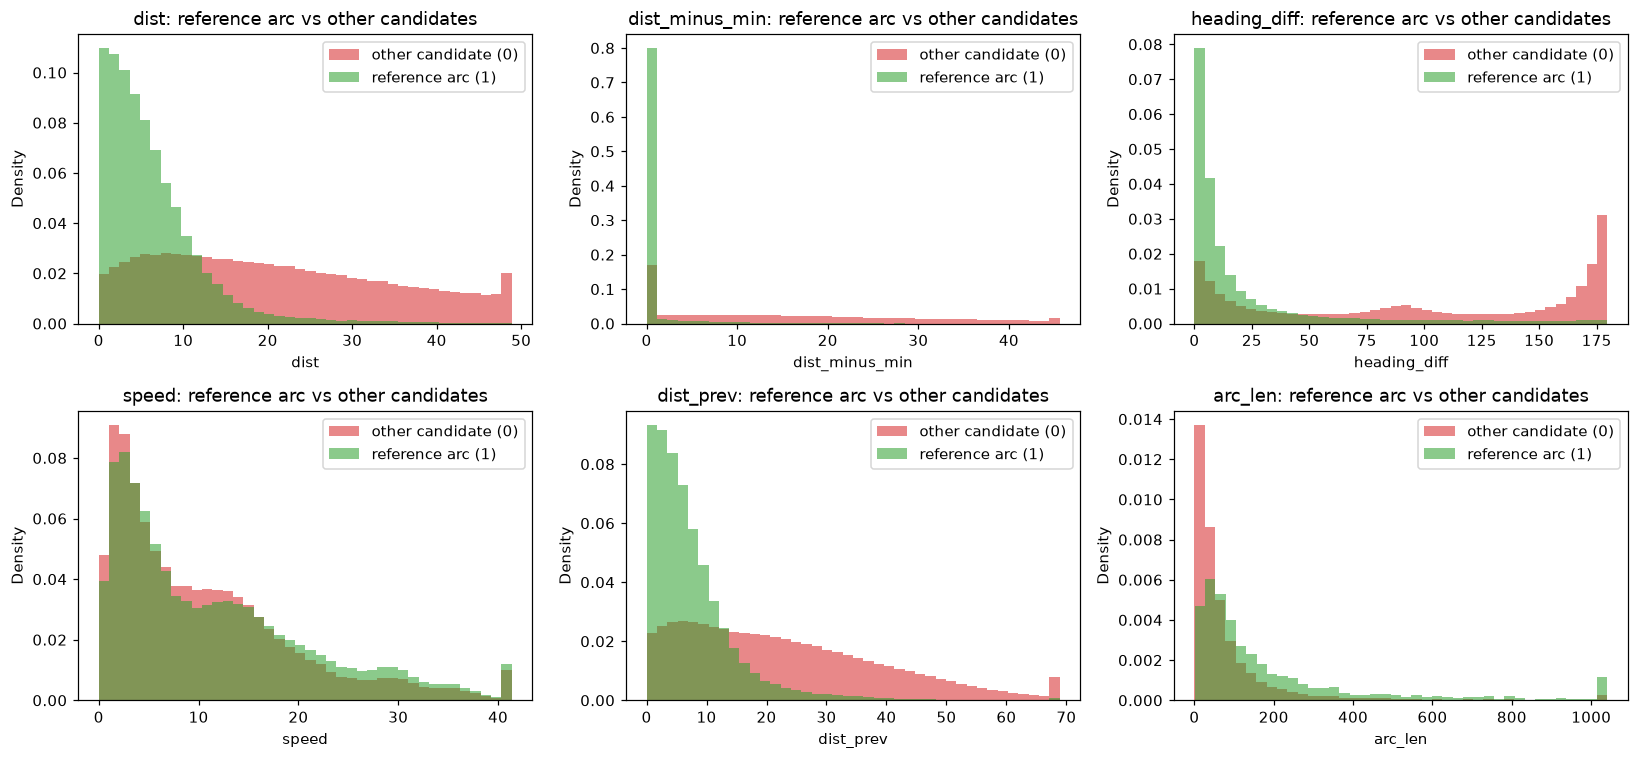

In [10]:
tv = cands[(cands.partition=='train') & (cands.valid==1)]
print('positives: %d  negatives: %d  -> positive share %.1f%%' % (tv.label.sum(), (tv.label==0).sum(), 100 * tv.label.mean()))
fig, ax = plt.subplots(2, 3, figsize=(15, 7)); ax = ax.ravel()
for k, f in enumerate(['dist','dist_minus_min','heading_diff','speed','dist_prev','arc_len']):
    lo, hi = np.percentile(tv[f], [0, 99])
    for lab, col, name in [(0,'tab:red','other candidate (0)'), (1,'tab:green','reference arc (1)')]:
        ax[k].hist(tv[tv.label==lab][f].clip(lo, hi), bins=40, alpha=.55, density=True, color=col, label=name)
    ax[k].set_title(f'{f}: reference arc vs other candidates'); ax[k].set_xlabel(f); ax[k].set_ylabel('Density'); ax[k].legend()
plt.tight_layout(); plt.savefig(f'{OUT}/feature_distributions.png'); plt.show()

**Why each feature**
| Feature | Why |
|---|---|
| `dist`, `dist_rank`, `dist_minus_min`, `dist_ratio` | GPS error is small (median about 5 m), so closer arcs are more likely |
| `heading_diff` | Arcs are directed: separates a road from its opposite direction and from cross streets |
| `speed` | When the car is slow or stopped, heading is noisy |
| `dist_prev`, `dist_next` | Context: the true arc stays close for neighbouring points too |
| `arc_len`, `t_along`, `n_cand`, `gap` | Road geometry, road density, GPS gaps |

All features are relative or in metres, so they transfer between cities.

## 6. Non-ML baseline: snap every point to the nearest road segment

In [11]:
res = []
for part in ['train', 'student_test']:
    s = cands[(cands.partition==part) & (cands.valid==1)]
    n_valid = sum(infos[k]['valid'].sum() for k in infos if k[0]==part)
    res.append(dict(partition=part, method='nearest arc (distance only)', top1_accuracy=s[s.dist_rank==0].label.sum() / n_valid))
base = pd.DataFrame(res); base.to_csv(f'{OUT}/baseline_nearest.csv', index=False); base.round(4)

,partition,method,top1_accuracy
0,train,nearest arc (distance only),0.5562
1,student_test,nearest arc (distance only),0.5369


In [12]:
tid = '00000000'; trip = load_trip('student_test', tid); t = trip['track']; nodes = trip['nodes'].values; arcs = trip['arcs'].values
s = cands[(cands.partition=='student_test') & (cands.trip_id==tid) & (cands.dist_rank==0)]
m = folium.Map(location=[t.lat.mean(), t.lon.mean()], zoom_start=14, tiles='cartodbpositron')
for name, arcs_ids, col, w in [('Reference route (green)', trip['route'], 'green', 6), ('Nearest-arc baseline (red)', s.arc_id.unique(), 'red', 3)]:
    g = folium.FeatureGroup(name)
    for a in arcs_ids:
        u, v = arcs[a]; folium.PolyLine([(nodes[u,1], nodes[u,0]), (nodes[v,1], nodes[v,0])], color=col, weight=w, opacity=.75).add_to(g)
    g.add_to(m)
g = folium.FeatureGroup('Raw GPS points (blue)')
for k, r in t.iloc[::3].iterrows(): folium.CircleMarker([r.lat, r.lon], radius=2, color='blue', fill=True).add_to(g)
g.add_to(m); folium.LayerControl(collapsed=False).add_to(m); m.fit_bounds([[t.lat.min(), t.lon.min()], [t.lat.max(), t.lon.max()]])
m.save(f'{MAPS}/02_student_test_{tid}_nearest_baseline.html'); m

The nearest-road rule is the bar every model must beat. It fails at junctions, on parallel roads and
on two-way roads (both directions are at the same distance).